In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/marketing_clean.csv", parse_dates=["Dt_Customer"])
print(df.shape)

(2051, 33)


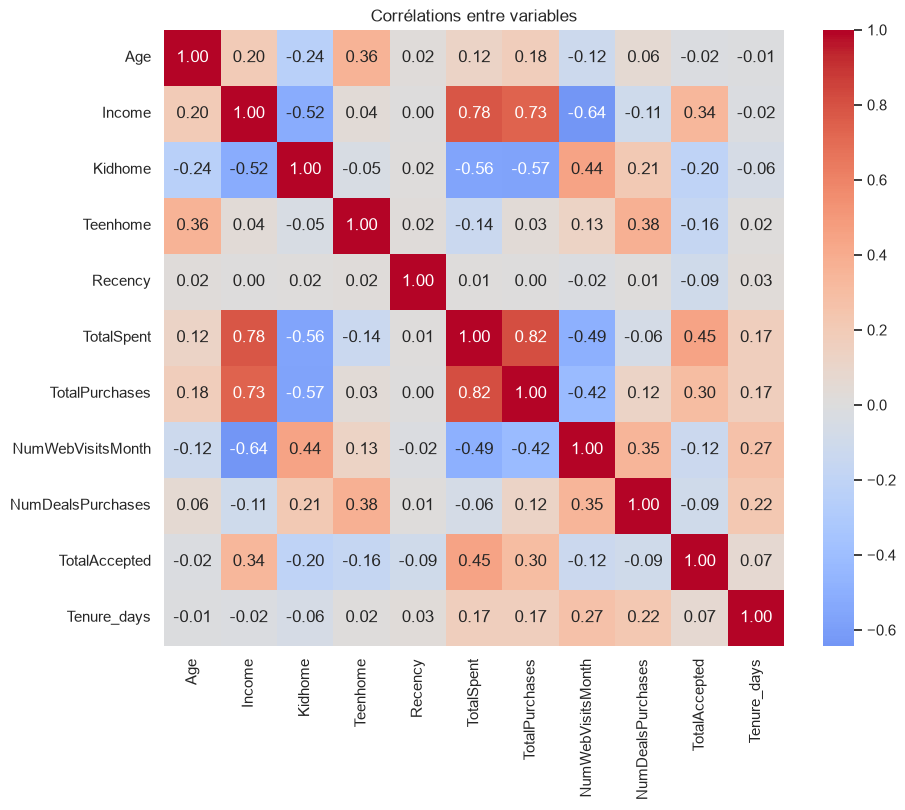

TotalSpent           1.00
TotalPurchases       0.82
Income               0.78
TotalAccepted        0.45
Tenure_days          0.17
Age                  0.12
Recency              0.01
NumDealsPurchases   -0.06
Teenhome            -0.14
NumWebVisitsMonth   -0.49
Kidhome             -0.56
Name: TotalSpent, dtype: float64


In [2]:
cols = ["Age", "Income", "Kidhome", "Teenhome", "Recency", "TotalSpent",
        "TotalPurchases", "NumWebVisitsMonth", "NumDealsPurchases",
        "TotalAccepted", "Tenure_days"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre variables")
plt.show()

print(df[cols].corr()["TotalSpent"].sort_values(ascending=False).round(2))

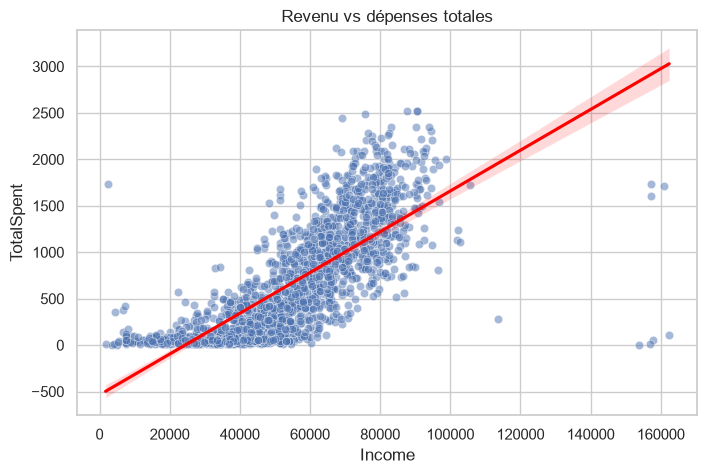

In [3]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Income", y="TotalSpent", alpha=0.5)
sns.regplot(data=df, x="Income", y="TotalSpent", scatter=False, color="red")
plt.title("Revenu vs dépenses totales")
plt.show()

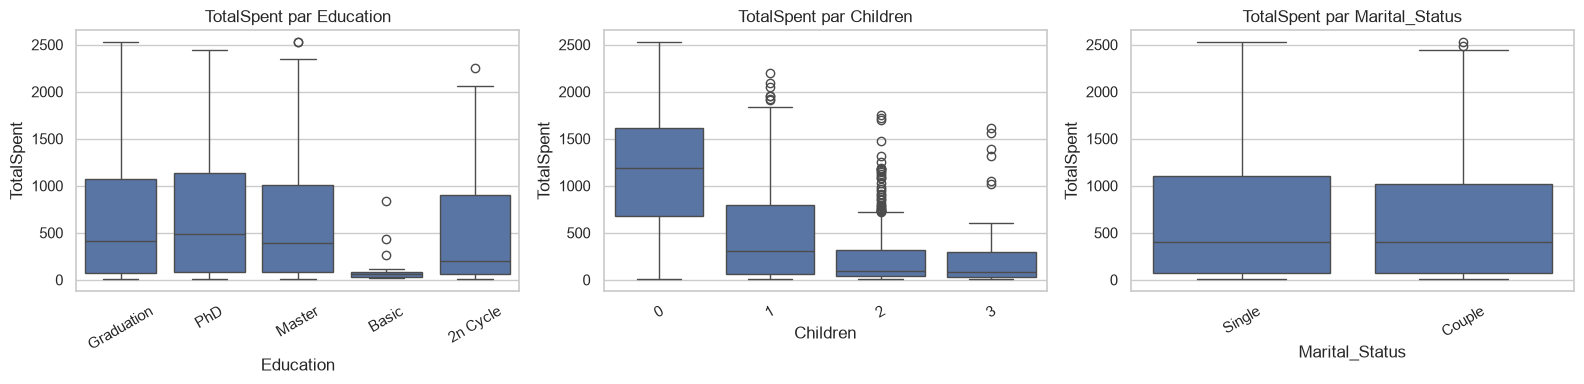

          count    mean  median
Children                       
0           576  1119.0  1192.0
1          1040   472.0   308.0
2           387   248.0    93.0
3            48   280.0    84.0
            count   mean  median
Education                       
2n Cycle      186  502.0   202.0
Basic          49   84.0    57.0
Graduation   1028  622.0   415.0
Master        341  620.0   395.0
PhD           447  662.0   484.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Education", "Children", "Marital_Status"]):
    sns.boxplot(data=df, x=col, y="TotalSpent", ax=ax)
    ax.set_title(f"TotalSpent par {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print(df.groupby("Children")["TotalSpent"].agg(["count", "mean", "median"]).round(0))
print(df.groupby("Education")["TotalSpent"].agg(["count", "mean", "median"]).round(0))

          NumWebPurchases  NumCatalogPurchases  NumStorePurchases
Children                                                         
0                    4.45                 4.79               7.31
1                    4.30                 2.14               5.57
2                    3.23                 1.11               4.29
3                    2.73                 1.04               3.96


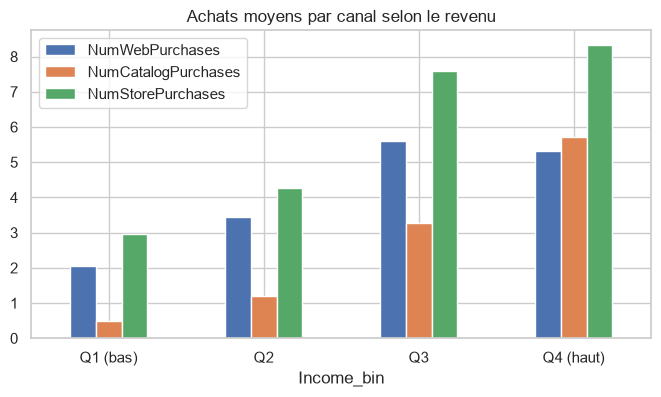

In [5]:
canaux = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

print(df.groupby("Children")[canaux].mean().round(2))

df["Income_bin"] = pd.qcut(df["Income"], 4, labels=["Q1 (bas)", "Q2", "Q3", "Q4 (haut)"])
df.groupby("Income_bin", observed=True)[canaux].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Achats moyens par canal selon le revenu")
plt.xticks(rotation=0)
plt.show()

           Age   Income  TotalSpent  Recency  TotalPurchases  Children
Response                                                              
0         45.2  50590.6       539.5     51.5            12.0       1.0
1         44.5  60242.8       984.8     35.2            15.3       0.6


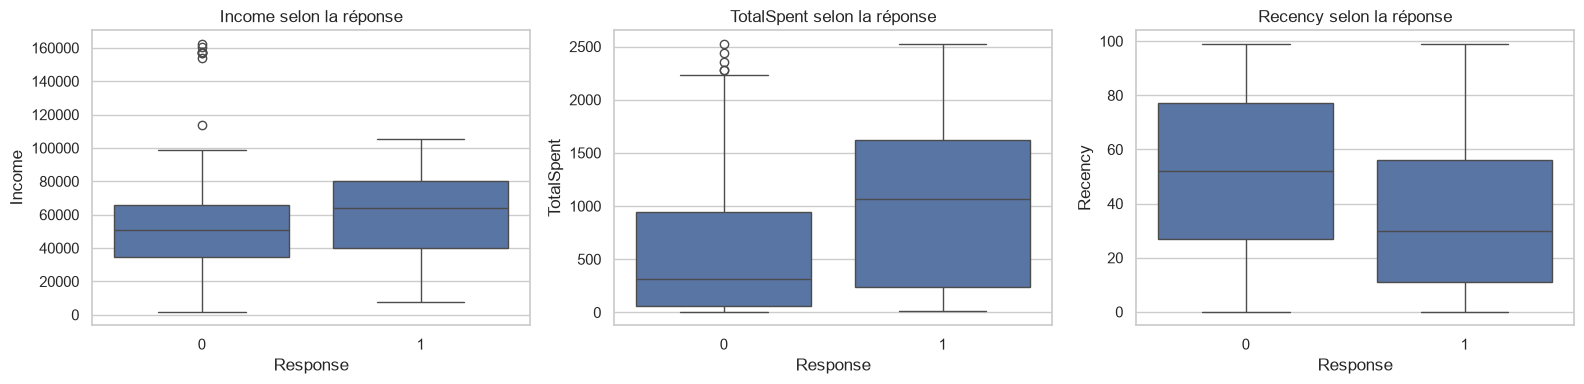

In [6]:
print(df.groupby("Response")[["Age", "Income", "TotalSpent", "Recency",
                              "TotalPurchases", "Children"]].mean().round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Income", "TotalSpent", "Recency"]):
    sns.boxplot(data=df, x="Response", y=col, ax=ax)
    ax.set_title(f"{col} selon la réponse")
plt.tight_layout()
plt.show()

Education
2n Cycle      11.8
Basic          4.1
Graduation    13.8
Master        15.8
PhD           20.4
Name: Response, dtype: float64 

Marital_Status
Couple    11.2
Single    22.3
Name: Response, dtype: float64 

Children
0    27.6
1    10.3
2    11.1
3     4.2
Name: Response, dtype: float64 

Income_bin
Q1 (bas)     10.7
Q2           11.8
Q3           11.0
Q4 (haut)    27.1
Name: Response, dtype: float64 



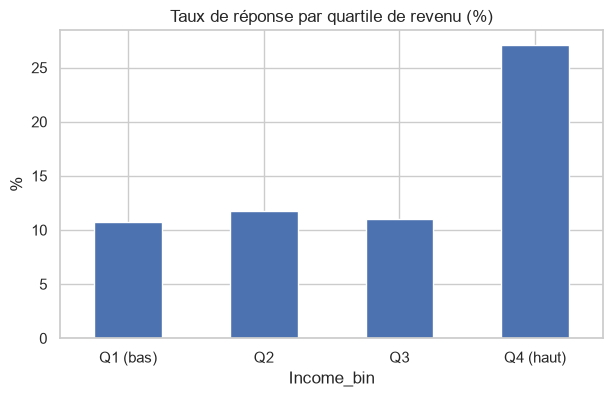

In [7]:
for col in ["Education", "Marital_Status", "Children", "Income_bin"]:
    print((df.groupby(col, observed=True)["Response"].mean() * 100).round(1), "\n")

(df.groupby("Income_bin", observed=True)["Response"].mean() * 100).plot(
    kind="bar", figsize=(7, 4), title="Taux de réponse par quartile de revenu (%)")
plt.xticks(rotation=0)
plt.ylabel("%")
plt.show()

In [8]:
from scipy import stats

oui = df.loc[df["Response"] == 1, "TotalSpent"]
non = df.loc[df["Response"] == 0, "TotalSpent"]

stat, p = stats.mannwhitneyu(oui, non)
print(f"Mann-Whitney U : p-value = {p:.2e}")

Mann-Whitney U : p-value = 2.35e-27


## Conclusions de l'étape 3

- Dépenses : fortement corrélées au revenu (0,78) et au nombre d'achats (0,82), négativement au nombre d'enfants en bas âge (-0,56) et aux visites web mensuelles (-0,49). La récence n'a aucun lien avec les dépenses.
- Enfants : les clients sans enfant dépensent en moyenne 1 119, contre 472 avec un enfant et 248 avec deux, soit 2 à 4 fois moins.
- Éducation : le niveau Basic dépense très peu ; les autres niveaux sont proches.
- Situation familiale : pas de différence notable de dépenses entre Single et Couple.
- Profil des répondants à la dernière campagne : revenu plus élevé (60 243 vs 50 591), dépenses presque doublées (985 vs 540), achat plus récent (35 vs 52 jours) et moins d'enfants (0,6 vs 1,0).
- Segments les plus réceptifs : clients sans enfant (27,6 %), Single (22,3 %) et titulaires d'un PhD (20,4 %). Le niveau Basic répond très peu (4,1 %).
-Limites : ces résultats montrent des corrélations, pas des causalités ; les effectifs sont faibles pour les clients avec 3 enfants et le niveau Basic.